In [20]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False
import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier,KNeighborsRegressor
from sklearn.linear_model import LinearRegression,Ridge,Lasso,LogisticRegression 
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.preprocessing import PolynomialFeatures,StandardScaler  
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax    # expit:이진분류,softmax:다중분류 0-1 숫자로 변환
from sklearn.linear_model import SGDClassifier

In [21]:
# 데이터 연결
fish = pd.read_csv('data/fish_logistic.csv')

In [22]:
# 데이터 분리
data = fish[fish.columns[1:]].values
label = fish['Species'].values
train_data,test_data,train_label,test_label = train_test_split(data,label,random_state=42)

In [23]:
# 정규화작업
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data) 

In [24]:
classes = train_label.unique()
classes = np.unique(train_label)

In [25]:
# lr = LogisticRegression()
# loss='log_loss': LogisticRegression log함수
# max_iter = 10 : 10번 반복
# random_stat3=42 : 랜덤선택을 고정 - 연습할때 랜덤으로 변경하면 정확도도 함께 변경이 되어서 고정시킴
# verbose=1 : 반복하면서 정보를 보여줌. / 설정하지 않으면 보여주지 않음.
sc = SGDClassifier(loss='log_loss',random_state=42)
train_score = []  # train정확도값 추가
test_score = []   # test정확도값 추가
# 정답지 필요
classes = np.unique(train_label)
for i in range(300):
    sc.partial_fit(train_scaled,train_label,classes=classes)
    train_score.append(sc.score(train_scaled,train_label))
    test_score.append(sc.score(test_scaled,test_label))

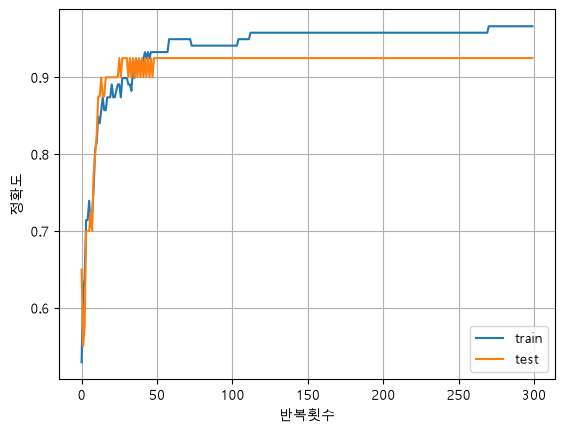

In [26]:
plt.plot(train_score)
plt.plot(test_score)
plt.xlabel('반복횟수')
plt.ylabel('정확도')
plt.grid()
plt.legend(['train','test'])
plt.show()